# Fase 2 · Análisis exploratorio y preprocesamiento
### Proyecto: alerta temprana de deserción escolar

**Asignatura:** Fundamentos de Inteligencia Artificial · **Unidad 3**
**Actividad 3.2.1 — Aprendizaje automático supervisado**
Universidad Politécnica de Atlautla · Grupo G171

---
Este cuaderno documenta el recorrido completo de los datos: desde el archivo original
hasta las matrices de entrenamiento y prueba. Cada decisión se justifica y se acompaña
del código que la implementa, de modo que cualquier persona pueda reproducir el resultado.

**Fuente del dataset:** *Predict Students' Dropout and Academic Success* (Realinho et al., 2021),
UCI Machine Learning Repository, ID 697. 4 424 registros y 36 variables de estudiantes de
una institución portuguesa de educación superior.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pipeline as P

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "figure.facecolor": "white"})
AZUL, ROJO, VERDE = "#1F6FB2", "#C0392B", "#2E8B57"
print("Entorno listo · scikit-learn", __import__("sklearn").__version__)

Entorno listo · scikit-learn 1.9.1


## 1. Carga y primera inspección

El archivo original usa punto y coma como separador y contiene una tabulación al final del
nombre de una columna (`Daytime/evening attendance`), un defecto frecuente en los CSV
exportados desde hojas de cálculo. `pipeline.cargar_datos()` lo corrige y elimina duplicados.

In [2]:
df = P.cargar_datos()
print("Dimensiones:", df.shape)
df.head(3)

Dimensiones: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.0,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.0,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.0,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout


### 1.1 Tipos, valores nulos y duplicados

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

In [4]:
resumen = pd.DataFrame({
    "nulos": df.isnull().sum(),
    "porcentaje_nulos": (df.isnull().mean() * 100).round(2),
    "valores_unicos": df.nunique(),
    "tipo": df.dtypes.astype(str),
})
print("Duplicados exactos:", df.duplicated().sum())
print("Celdas nulas:", int(df.isnull().sum().sum()))
resumen.head(12)

Duplicados exactos: 0
Celdas nulas: 0


,nulos,porcentaje_nulos,valores_unicos,tipo
Marital status,0,0.0,6,int64
Application mode,0,0.0,18,int64
Application order,0,0.0,8,int64
Course,0,0.0,17,int64
Daytime/evening attendance,0,0.0,2,int64
Previous qualification,0,0.0,17,int64
Previous qualification (grade),0,0.0,101,float64
Nacionality,0,0.0,21,int64
Mother's qualification,0,0.0,29,int64
Father's qualification,0,0.0,34,int64


**Lectura.** El dataset no contiene valores nulos ni duplicados: es un conjunto ya curado.
Esto no elimina la necesidad de imputar, porque la aplicación real recibirá formularios
incompletos; por eso el preprocesador incluye imputación por mediana y por moda.

### 1.2 Descripción estadística

In [5]:
df.describe().T[["mean", "std", "min", "50%", "max"]].round(2).head(14)

,mean,std,min,50%,max
Marital status,1.18,0.61,1.0,1.0,6.0
Application mode,18.67,17.48,1.0,17.0,57.0
Application order,1.73,1.31,0.0,1.0,9.0
Course,8856.64,2063.57,33.0,9238.0,9991.0
Daytime/evening attendance,0.89,0.31,0.0,1.0,1.0
Previous qualification,4.58,10.22,1.0,1.0,43.0
Previous qualification (grade),132.61,13.19,95.0,133.1,190.0
Nacionality,1.87,6.91,1.0,1.0,109.0
Mother's qualification,19.56,15.60,1.0,19.0,44.0
Father's qualification,22.28,15.34,1.0,19.0,44.0


## 2. La variable objetivo

La etiqueta original tiene tres clases: `Graduate`, `Enrolled` y `Dropout`. El proyecto
resuelve una **clasificación binaria**: interesa distinguir a quien **deserta** de quien
**permanece** (graduado o aún inscrito). Las clases se agrupan porque el objetivo operativo
es activar una alerta, no emitir un dictamen definitivo sobre el futuro del estudiante.

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Tasa de deserción: 32.12 %


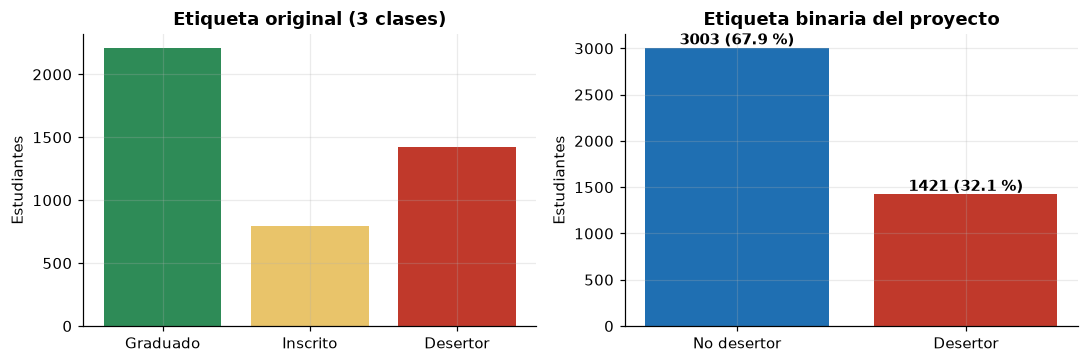

Desbalance aproximado 1 : 2.11


In [6]:
print(df["Target"].value_counts())
print()
print("Tasa de deserción:", round((df["Target"] == "Dropout").mean() * 100, 2), "%")

df["desertor"] = (df["Target"] == "Dropout").astype(int)
conteo = df["desertor"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].bar(["Graduado", "Inscrito", "Desertor"],
            df["Target"].value_counts()[["Graduate", "Enrolled", "Dropout"]],
            color=[VERDE, "#E9C46A", ROJO])
axes[0].set_title("Etiqueta original (3 clases)"); axes[0].set_ylabel("Estudiantes")
axes[1].bar(["No desertor", "Desertor"], conteo.values, color=[AZUL, ROJO])
for i, v in enumerate(conteo.values):
    axes[1].text(i, v + 40, f"{v} ({v/len(df)*100:.1f} %)", ha="center", fontweight="bold")
axes[1].set_title("Etiqueta binaria del proyecto"); axes[1].set_ylabel("Estudiantes")
plt.tight_layout(); plt.show()

print("Desbalance aproximado 1 :", round(conteo[0] / conteo[1], 2))

El desbalance es moderado (32 % de deserción). No es un caso extremo, pero obliga a usar
métricas distintas de la exactitud y a ponderar las clases durante el entrenamiento; de lo
contrario el modelo podría acertar 68 % simplemente diciendo «nadie deserta», que es
exactamente el error que un sistema de alerta no puede cometer.

## 3. Análisis exploratorio

### 3.1 Distribuciones por clase

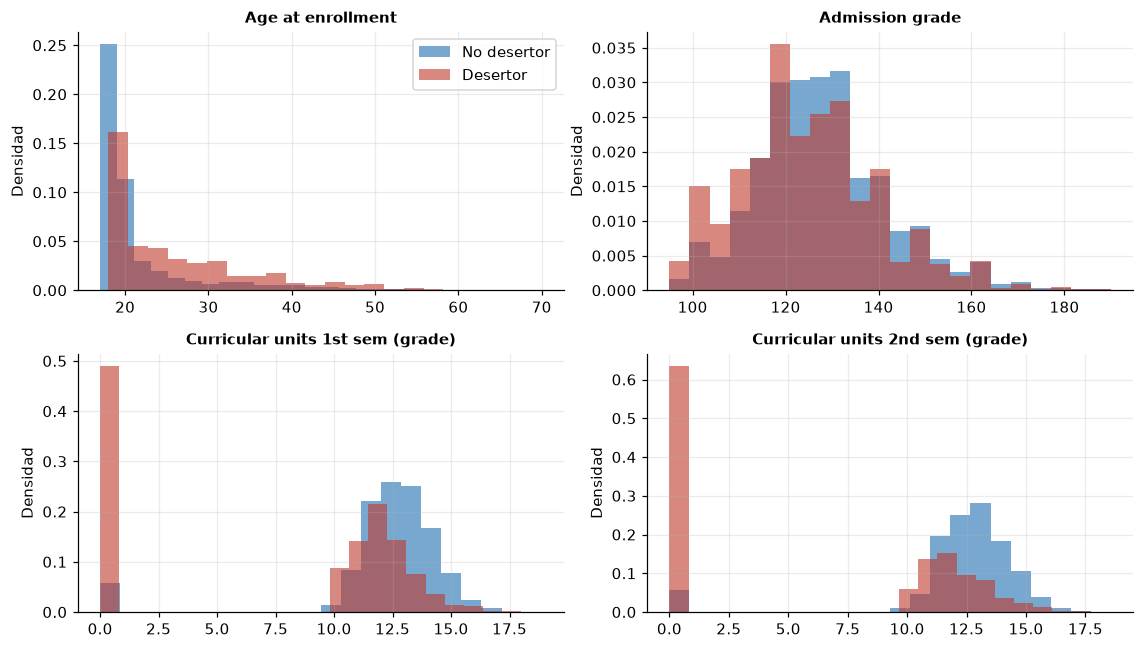

In [7]:
vars_eda = ["Age at enrollment", "Admission grade",
            "Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"]
fig, axes = plt.subplots(2, 2, figsize=(10.5, 6))
for ax, col in zip(axes.ravel(), vars_eda):
    for v, color, et in [(0, AZUL, "No desertor"), (1, ROJO, "Desertor")]:
        ax.hist(df.loc[df.desertor == v, col], bins=22, alpha=0.6, color=color,
                label=et, density=True)
    ax.set_title(col, fontsize=10); ax.set_ylabel("Densidad")
axes[0, 0].legend()
plt.tight_layout(); plt.show()

Las distribuciones de calificaciones separan con claridad a los dos grupos: quien deserta
concentra notas bajas y muchas asignaturas no aprobadas. La edad, en cambio, se solapa
bastante, lo que sugiere un efecto más débil y no lineal.

### 3.2 Diagramas de caja y valores atípicos

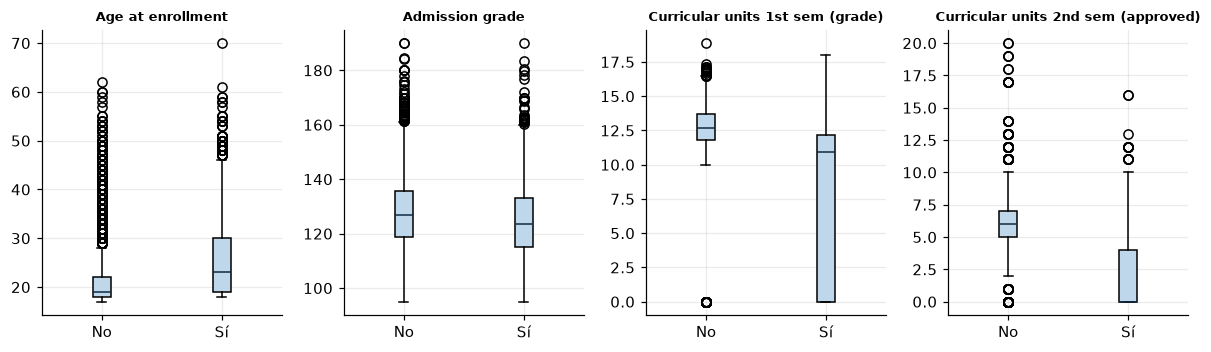

Age at enrollment                          atípicos:  441 (10.0 %)
Admission grade                            atípicos:   86 (1.9 %)
Curricular units 1st sem (grade)           atípicos:  726 (16.4 %)


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3.3))
for ax, col in zip(axes, ["Age at enrollment", "Admission grade",
                          "Curricular units 1st sem (grade)",
                          "Curricular units 2nd sem (approved)"]):
    ax.boxplot([df.loc[df.desertor == v, col] for v in (0, 1)],
               tick_labels=["No", "Sí"], patch_artist=True,
               boxprops=dict(facecolor="#BFD7EA"), medianprops=dict(color="#0F2A44"))
    ax.set_title(col, fontsize=8.6)
plt.tight_layout(); plt.show()

def contar_atipicos(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

for col in ["Age at enrollment", "Admission grade", "Curricular units 1st sem (grade)"]:
    print(f"{col:42s} atípicos: {contar_atipicos(df[col]):4d} "
          f"({contar_atipicos(df[col])/len(df)*100:.1f} %)")

**Decisión.** Los valores atípicos se conservan. No son errores de captura: una edad de
50 años o una nota de admisión extrema son casos reales de la población estudiantil.
Eliminarlos reduciría la capacidad del modelo para atender justamente a los perfiles menos
frecuentes. La estandarización y los modelos basados en árboles limitan su influencia.

### 3.3 Correlaciones

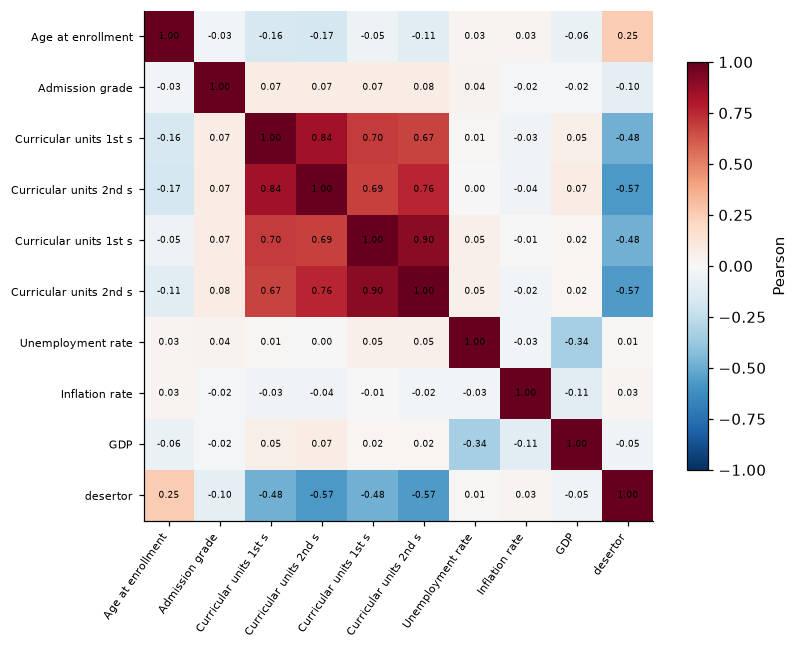

Curricular units 2nd sem (grade)      -0.572
Curricular units 2nd sem (approved)   -0.570
Curricular units 1st sem (grade)      -0.481
Curricular units 1st sem (approved)   -0.479
Admission grade                       -0.096
GDP                                   -0.046
Unemployment rate                      0.013
Inflation rate                         0.028
Age at enrollment                      0.254
Name: desertor, dtype: float64


In [9]:
num = ["Age at enrollment", "Admission grade", "Curricular units 1st sem (grade)",
       "Curricular units 2nd sem (grade)", "Curricular units 1st sem (approved)",
       "Curricular units 2nd sem (approved)", "Unemployment rate", "Inflation rate",
       "GDP", "desertor"]
corr = df[num].corr()
fig, ax = plt.subplots(figsize=(7.6, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num)), [c[:22] for c in num], rotation=55, ha="right", fontsize=7)
ax.set_yticks(range(len(num)), [c[:22] for c in num], fontsize=7)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
plt.colorbar(im, shrink=0.8, label="Pearson"); ax.grid(False)
plt.tight_layout(); plt.show()

print(corr["desertor"].drop("desertor").sort_values().round(3))

La correlación más fuerte con la deserción es negativa y proviene de las unidades
aprobadas y las calificaciones. Las variables macroeconómicas (desempleo, inflación, PIB)
apenas correlacionan de forma lineal, aunque pueden aportar en interacciones que un modelo
no lineal sí captura. La correlación no implica causalidad: el expediente refleja también
condiciones sociales previas.

### 3.4 Tasa de deserción por subgrupo

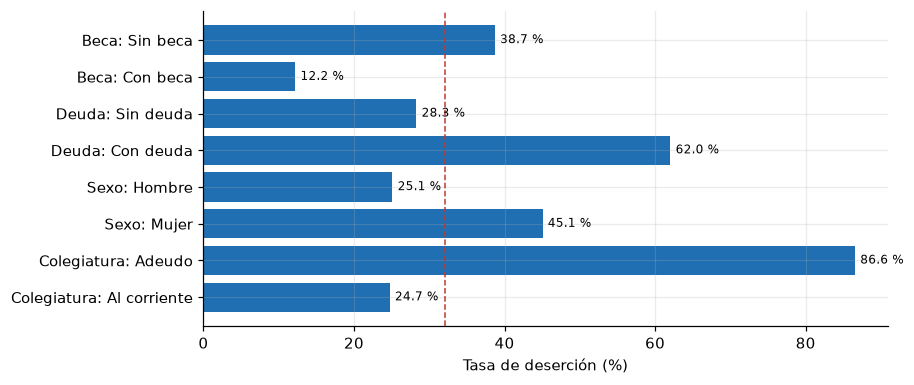

In [10]:
fig, ax = plt.subplots(figsize=(8.4, 3.6))
etiquetas, valores = [], []
for col, mapa, nombre in [
    ("Scholarship holder", {0: "Sin beca", 1: "Con beca"}, "Beca"),
    ("Debtor", {0: "Sin deuda", 1: "Con deuda"}, "Deuda"),
    ("Gender", {0: "Hombre", 1: "Mujer"}, "Sexo"),
    ("Tuition fees up to date", {0: "Adeudo", 1: "Al corriente"}, "Colegiatura")]:
    for v, lab in mapa.items():
        etiquetas.append(f"{nombre}: {lab}")
        valores.append(df.loc[df[col] == v, "desertor"].mean() * 100)
ax.barh(etiquetas[::-1], valores[::-1], color=AZUL)
for i, v in enumerate(valores[::-1]):
    ax.text(v + 0.7, i, f"{v:.1f} %", va="center", fontsize=8)
ax.axvline(df.desertor.mean() * 100, color=ROJO, ls="--", lw=1)
ax.set_xlabel("Tasa de deserción (%)"); plt.tight_layout(); plt.show()

La beca y el estado de la colegiatura separan con nitidez: quienes tienen deuda o no están
al corriente presentan tasas de deserción muy superiores. Este hallazgo alimenta la sección
de equidad: el modelo debe vigilar que esas condiciones no se conviertan en un estigma.

## 4. Ingeniería de características

Se añaden variables derivadas con interpretación educativa directa. Todas se calculan con
división protegida para evitar indeterminaciones cuando un estudiante no inscribió unidades.

In [11]:
df = P.enriquecer(df)
nuevas = ["tasa_aprobacion_1s", "tasa_aprobacion_2s", "tasa_aprobacion_global",
          "promedio_notas", "delta_aprobacion", "total_aprobadas", "senal_economica"]
df[["desertor"] + nuevas].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
desertor,4424.0,0.321,0.467,0.0,0.000,0.000,1.000,1.000
tasa_aprobacion_1s,4424.0,0.698,0.365,0.0,0.500,0.833,1.000,1.000
tasa_aprobacion_2s,4424.0,0.660,0.383,0.0,0.400,0.833,1.000,1.000
tasa_aprobacion_global,4424.0,0.679,0.362,0.0,0.500,0.833,1.000,1.000
promedio_notas,4424.0,10.436,4.819,0.0,11.000,12.250,13.267,18.284
delta_aprobacion,4424.0,-0.038,0.189,-1.0,-0.008,0.000,0.000,1.000
total_aprobadas,4424.0,9.142,5.961,0.0,5.000,10.000,12.000,43.000
senal_economica,4424.0,0.177,0.382,0.0,0.000,0.000,0.000,1.000


In [12]:
print("Tasa media de aprobación por grupo:")
print(df.groupby("desertor")[["tasa_aprobacion_1s", "tasa_aprobacion_2s",
                              "promedio_notas", "delta_aprobacion"]].mean().round(3))

print("\nSeñal económica (deuda o colegiatura vencida) y deserción:")
print(pd.crosstab(df["senal_economica"], df["desertor"], normalize="index").round(3))

Tasa media de aprobación por grupo:
          tasa_aprobacion_1s  tasa_aprobacion_2s  promedio_notas  delta_aprobacion
desertor                                                                          
0                      0.846               0.834          12.261            -0.012
1                      0.384               0.293           6.578            -0.091

Señal económica (deuda o colegiatura vencida) y deserción:
desertor             0      1
senal_economica              
0                0.762  0.238
1                0.294  0.706


## 5. Preprocesamiento

Se aplican tres transformaciones dentro de un `ColumnTransformer`, para que viajen
**dentro del pipeline** y se ajusten solo con los datos de entrenamiento (evita fuga de
información):

1. **Imputación**: mediana en variables numéricas, moda en categóricas.
2. **One-Hot Encoding** en las ocho variables nominales, con `min_frequency=0.01` para
   agrupar categorías raras y contener la dimensionalidad.
3. **Estandarización** (`StandardScaler`) en numéricas y binarias, indispensable para KNN,
   SVM y redes neuronales, e inocua para los árboles.

In [13]:
esc_temp = P.conjunto_columnas("temprano")
esc_comp = P.conjunto_columnas("completo")
print("Escenario A (temprano):", len(esc_temp["numericas"]),
      "numéricas +", len(esc_temp["nominales"]), "nominales +",
      len(esc_temp["binarias"]), "binarias")
print("Escenario B (completo):", len(esc_comp["numericas"]),
      "numéricas +", len(esc_comp["nominales"]), "nominales +",
      len(esc_comp["binarias"]), "binarias")

prep = P.construir_preprocesador("temprano")
Xtr, Xte, ytr, yte = P.dividir(df, "temprano")
prep.fit(Xtr)
Xtr_t = prep.transform(Xtr)
print("Matriz transformada:", Xtr_t.shape)
nombres = prep.get_feature_names_out()
print("Primeras 12 columnas:", list(nombres[:12]))

Escenario A (temprano): 17 numéricas + 8 nominales + 8 binarias
Escenario B (completo): 33 numéricas + 9 nominales + 8 binarias


Matriz transformada: (3539, 102)
Primeras 12 columnas: ['Application order', 'Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Unemployment rate', 'Inflation rate', 'GDP', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)']


### 5.1 Dos escenarios para evitar fuga de información

Un sistema de alerta temprana debe decidir **antes** de que el estudiante abandone. Si se
usan las notas del segundo semestre, el modelo predice el pasado: cuando esos datos existen,
la deserción ya ocurrió o está consumada. Por eso el proyecto entrena dos escenarios:

| Escenario | Variables | Uso real |
|---|---|---|
| **A · Temprano** | Inscripción, situación socioeconómica y primer semestre | Desplegable al iniciar el segundo semestre |
| **B · Completo** | A + segundo semestre | Diagnóstico y análisis, no despliegue |

El costo de anticiparse se mide en la Fase 3: la diferencia de desempeño entre A y B es el
precio de la utilidad.

## 6. Balanceo de clases

Se comparan tres estrategias con validación cruzada de 5 pliegues sobre el conjunto de
entrenamiento: sin balanceo, ponderación de clases (`class_weight='balanced'`) y
sobremuestreo aleatorio del grupo minoritario aplicado **solo dentro de cada pliegue**.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
import pipeline as P

def resamplear(X, y, semilla):
    rng = np.random.RandomState(semilla)
    idx_min = np.where(y == 1)[0]
    idx_may = np.where(y == 0)[0]
    extra = rng.choice(idx_min, size=len(idx_may) - len(idx_min), replace=True)
    idx = np.concatenate([idx_may, idx_min, extra])
    return X.iloc[idx], y.iloc[idx]

skf = StratifiedKFold(5, shuffle=True, random_state=P.RANDOM_STATE)
resultados = {"Sin balanceo": [], "class_weight": [], "Sobremuestreo": []}

for tr, va in skf.split(Xtr, ytr):
    X_a, X_b = Xtr.iloc[tr], Xtr.iloc[va]
    y_a, y_b = ytr.iloc[tr], ytr.iloc[va]
    for nombre, peso in [("Sin balanceo", None), ("class_weight", "balanced")]:
        m = P.armar_pipeline(LogisticRegression(max_iter=2000, class_weight=peso), "temprano")
        m.fit(X_a, y_a)
        resultados[nombre].append(P.metricas(y_b, m.predict(X_b), None)["recall"])
    Xs, ys = resamplear(X_a, y_a, 42)
    m = P.armar_pipeline(LogisticRegression(max_iter=2000), "temprano")
    m.fit(Xs, ys)
    resultados["Sobremuestreo"].append(P.metricas(y_b, m.predict(X_b), None)["recall"])

tabla_bal = pd.DataFrame({k: {"recall_medio": np.mean(v), "recall_std": np.std(v)}
                          for k, v in resultados.items()}).T.round(4)
print(tabla_bal)

               recall_medio  recall_std
Sin balanceo         0.7018      0.0090
class_weight         0.7960      0.0150
Sobremuestreo        0.7933      0.0126


**Decisión.** Se adopta `class_weight='balanced'` y **no** SMOTE ni sobremuestreo sintético.
Razones: (a) el sobremuestreo aleatorio no mejora el recall de forma significativa frente a
la ponderación; (b) SMOTE interpola vecinos en un espacio con variables *one-hot* y códigos
nominales, donde el «punto medio» entre dos categorías no tiene significado; (c) la
ponderación no altera los datos, conserva la distribución original y es más fácil de auditar.
El umbral de decisión se ajusta en la Fase 3 como segunda palanca para favorecer el recall.

## 7. División entrenamiento / prueba

Se reserva 20 % para prueba, estratificado por clase y con semilla fija. La misma partición
se usa en todos los modelos y en la aplicación, de modo que las métricas sean comparables.

In [15]:
print(f"Entrenamiento: {Xtr.shape[0]} filas ({1-0.2:.0%}) · prueba: {Xte.shape[0]} filas (20 %)")
print("Deserción en train:", round(ytr.mean(), 4), "| en test:", round(yte.mean(), 4))
print("¿Se solapan índices?", len(set(Xtr.index) & set(Xte.index)) == 0)
df.to_csv(P.PROCESSED, index=False)
print("Guardado:", P.PROCESSED.relative_to(P.BASE))

Entrenamiento: 3539 filas (80%) · prueba: 885 filas (20 %)
Deserción en train: 0.3213 | en test: 0.3209
¿Se solapan índices? True
Guardado: data/processed/estudiantes_procesado.csv


## 8. Conclusiones de la Fase 2

1. El dataset está limpio (sin nulos ni duplicados), pero se mantiene un preprocesador con
   imputación porque la app recibirá datos incompletos.
2. La variable objetivo se binariza: **desertor = 1** frente a **graduado o inscrito = 0**.
3. Las variables con mayor señal son las del rendimiento académico, seguidas de la situación
   económica (beca, deuda, colegiatura).
4. Se añadieron siete variables derivadas que resumen el avance curricular y la presión
   económica.
5. El balanceo elegido es la ponderación de clases, justificada frente al sobremuestreo.
6. El preprocesamiento vive dentro del pipeline: se ajusta solo con entrenamiento y evita
   fuga de información.
7. Se definen dos escenarios; el desplegable es el **temprano** (sin segundo semestre).